# Where the music comes from
Share of plays by the artist's country of origin.

## Load data
Uses `scrobbles.parquet` and `artist_countries.parquet` from the project folder, or `sample_data/` if they aren't there.

In [1]:
import os
import json
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Patch
from matplotlib.ticker import PercentFormatter

from viz import BAR_COLOR, BLUE_RAMP, SURFACE, INK, INK_SECONDARY, MUTED, GRID, BASELINE, add_title, save_figure

DATA_DIR = '.' if os.path.exists('scrobbles.parquet') else 'sample_data'  # falls back to the bundled sample
print(f'data: {DATA_DIR}')

df = pd.read_parquet(f'{DATA_DIR}/scrobbles.parquet')
countries = pd.read_parquet(f'{DATA_DIR}/artist_countries.parquet')
print(df.shape, countries.shape)

/Users/samkumagai/miniforge3/envs/py312/lib/python3.12/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


data: .
(33736, 5) (1169, 2)


## Country outlines
Natural Earth 1:110m country polygons, downloaded once into `cache/`. The shapes are projected with the Equal Earth formula, which keeps areas comparable, so no mapping library is needed.

In [2]:
WORLD_URL = 'https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson'
WORLD_FILE = 'cache/ne_110m_admin_0_countries.geojson'

if not os.path.exists(WORLD_FILE):
    os.makedirs('cache', exist_ok=True)
    response = requests.get(WORLD_URL, timeout=60)
    response.raise_for_status()
    with open(WORLD_FILE, 'wb') as f:
        f.write(response.content)

with open(WORLD_FILE) as f:
    features = json.load(f)['features']

A1, A2, A3, A4 = 1.340264, -0.081106, 0.000893, 0.003796  # Equal Earth coefficients


def project(lon, lat):
    '''Equal Earth projection of longitude and latitude in degrees.'''
    lon, lat = np.radians(lon), np.radians(lat)
    theta = np.arcsin(np.sqrt(3) / 2 * np.sin(lat))
    t2, t6 = theta ** 2, theta ** 6
    x = 2 * np.sqrt(3) * lon * np.cos(theta) / (3 * (A1 + 3 * A2 * t2 + t6 * (7 * A3 + 9 * A4 * t2)))
    y = theta * (A1 + A2 * t2 + t6 * (A3 + A4 * t2))
    return x, y


def to_path(polygon):
    '''Matplotlib path for one polygon: the outer ring first, then any holes.'''
    vertices, codes = [], []
    for ring in polygon:
        x, y = project(*np.array(ring)[:, :2].T)
        vertices.append(np.column_stack([x, y]))
        codes += [Path.MOVETO] + [Path.LINETO] * (len(ring) - 2) + [Path.CLOSEPOLY]
    return Path(np.vstack(vertices), codes)


world = {}  # ISO alpha-2 code -> name and projected outlines
for feature in features:
    props = {key.upper(): value for key, value in feature['properties'].items()}
    code = props.get('ISO_A2_EH')
    if code is None or len(code) != 2:  # the _EH column fills in France, Norway and others
        code = props.get('ISO_A2')
    if code is None or len(code) != 2 or props.get('CONTINENT') == 'Antarctica':
        continue
    geometry = feature['geometry']
    polygons = [geometry['coordinates']] if geometry['type'] == 'Polygon' else geometry['coordinates']
    world[code] = {'name': props.get('NAME') or props.get('ADMIN') or code,
                   'paths': [to_path(polygon) for polygon in polygons]}
print(f'{len(world)} countries')

174 countries


## Plays by country
Plays by artists without a known country are left out of the shares. The line below shows how much that is.

In [3]:
TOP_N = 10  # countries in the bar chart

plays = df[['artist']].merge(countries, on='artist', how='left')  # country is empty for artists MusicBrainz doesn't place
known = plays.dropna(subset=['country'])
coverage = len(known) / len(plays)
print(f'{coverage:.0%} of plays have a known country')

share = known.groupby('country').size().sort_values(ascending=False) / len(known) * 100  # percent of plays with a country
share.head(TOP_N)

89% of plays have a known country


country
US    59.863493
GB    20.186449
CA     4.548027
FR     4.161811
AU     2.833361
JP     1.584818
DE     0.785750
PR     0.775762
NL     0.739138
IE     0.675878
dtype: float64

## Map and ranking
Countries are shaded by share of plays in a few classes, with the top countries ranked below the map. Countries with no plays stay gray.

findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.
findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


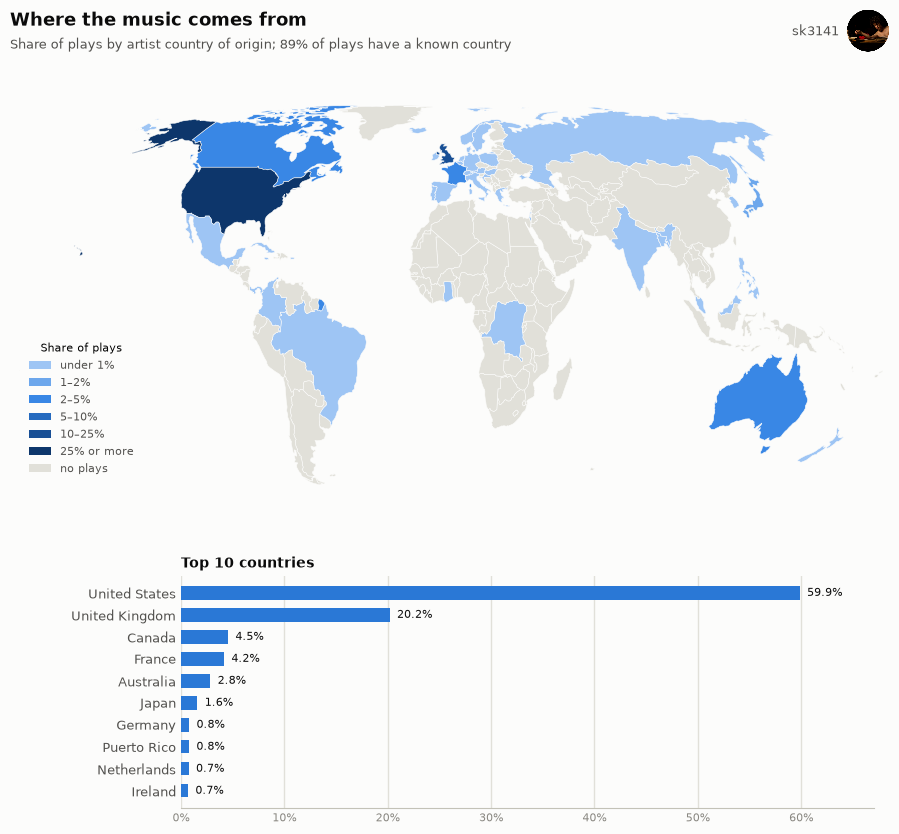

In [4]:
BINS = [1, 2, 5, 10, 25]  # class boundaries for the map, in percent of plays
NO_PLAYS = GRID
SHORT_NAMES = {'United States of America': 'United States'}  # Natural Earth's longer names, for the bar labels

colors = BLUE_RAMP[-(len(BINS) + 1):]  # darker for a larger share
class_labels = ([f'under {BINS[0]}%'] + [f'{lo}–{hi}%' for lo, hi in zip(BINS, BINS[1:])]
                + [f'{BINS[-1]}% or more'])


def plot_countries(share, save=False):
    '''Map of play share by country with a ranked bar chart of the top countries below it.'''
    height = 8.6
    fig = plt.figure(figsize=(9, height), facecolor=SURFACE)
    title_edge = 1 - 0.75 / height  # leave room for the title
    map_ax = fig.add_subplot(fig.add_gridspec(1, 1, left=0.02, right=0.98, top=title_edge, bottom=0.40)[0])
    bar_ax = fig.add_subplot(fig.add_gridspec(1, 1, left=0.2, right=0.97, top=0.33, bottom=0.06)[0])

    classes = pd.Series(np.digitize(share, BINS), index=share.index)  # 0 .. len(BINS)
    x_range, y_range = [np.inf, -np.inf], [np.inf, -np.inf]
    for code, shape in world.items():
        color = colors[classes[code]] if code in classes.index else NO_PLAYS
        for path in shape['paths']:
            map_ax.add_patch(PathPatch(path, facecolor=color, edgecolor=SURFACE, linewidth=0.4))
            x_range = [min(x_range[0], path.vertices[:, 0].min()), max(x_range[1], path.vertices[:, 0].max())]
            y_range = [min(y_range[0], path.vertices[:, 1].min()), max(y_range[1], path.vertices[:, 1].max())]
    map_ax.set_xlim(*x_range)
    map_ax.set_ylim(*y_range)
    map_ax.set_aspect('equal')
    map_ax.set_axis_off()

    handles = [Patch(facecolor=c, edgecolor='none') for c in colors] + [Patch(facecolor=NO_PLAYS, edgecolor='none')]
    map_ax.legend(handles, class_labels + ['no plays'], loc='lower left', frameon=False, fontsize=8,
                  title='Share of plays', title_fontsize=8, labelcolor=INK_SECONDARY)

    top = share.head(TOP_N)[::-1]  # reversed so the largest is at the top
    names = [world[code]['name'] if code in world else code for code in top.index]
    names = [SHORT_NAMES.get(name, name) for name in names]
    bar_ax.barh(names, top.values, height=0.6, color=BAR_COLOR)
    for y, value in enumerate(top.values):
        bar_ax.text(value + top.max() * 0.012, y, f'{value:.1f}%', va='center', fontsize=8, color=INK)
    bar_ax.set_title(f'Top {len(top)} countries', loc='left', fontsize=10, fontweight='bold', color=INK)
    bar_ax.set_facecolor(SURFACE)
    bar_ax.set_xlim(0, top.max() * 1.12)
    bar_ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    bar_ax.xaxis.grid(True, color=GRID, linewidth=1)
    bar_ax.set_axisbelow(True)
    for side in ('top', 'right', 'left'):
        bar_ax.spines[side].set_visible(False)
    bar_ax.spines['bottom'].set_color(BASELINE)
    bar_ax.tick_params(length=0, labelsize=8, labelcolor=MUTED)
    bar_ax.tick_params(axis='y', labelsize=9, labelcolor=INK_SECONDARY)

    add_title(fig, 'Where the music comes from',
              f'Share of plays by artist country of origin; {coverage:.0%} of plays have a known country', height)
    if save:
        save_figure(fig, 'plays_by_country')
    plt.show()


plot_countries(share, save=True)

## Top artists in each country
The most played artists from each of the top countries. Each panel is scaled to its own top artist, so the bars compare artists within a country.

In [5]:
TOP_COUNTRIES = 6  # countries to show, by plays
TOP_ARTISTS = 5  # artists per country

by_artist = known.groupby(['country', 'artist']).size().rename('plays').reset_index()
top_countries = known['country'].value_counts().head(TOP_COUNTRIES).index  # most played countries, largest first

country_artists = (by_artist[by_artist['country'].isin(top_countries)]
                   .sort_values(['country', 'plays'], ascending=[True, False])
                   .groupby('country')
                   .head(TOP_ARTISTS))
country_artists.head()

,country,artist,plays
30,AU,Tame Impala,335
31,AU,The Avalanches,224
11,AU,Empire of the Sun,37
32,AU,The Jungle Giants,37
19,AU,Mallrat,33


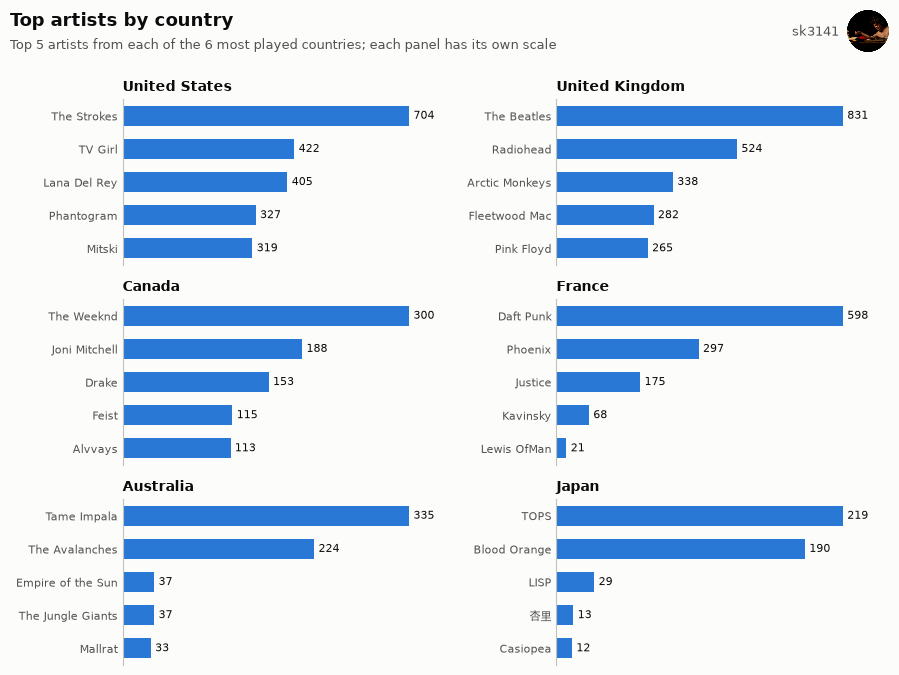

In [6]:
def plot_country_artists(country_artists, top_countries, save=False):
    '''One panel per country with that country's most played artists.'''
    n_cols = 2
    n_rows = -(-len(top_countries) // n_cols)  # ceiling division
    height = 1.9 * n_rows + 1.1
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(9, height), facecolor=SURFACE, squeeze=False)

    for ax, code in zip(axes.flat, top_countries):
        rows = country_artists[country_artists['country'] == code].sort_values('plays', ascending=False)
        names = [name if len(name) <= 24 else name[:23] + '…' for name in rows['artist']]
        ax.barh(names, rows['plays'], height=0.6, color=BAR_COLOR)
        ax.set_ylim(TOP_ARTISTS - 0.5, -0.5)  # largest at the top; a fixed range keeps the bars equally thick in every panel
        for y, value in enumerate(rows['plays']):
            ax.text(value + rows['plays'].max() * 0.015, y, f'{value:,}', va='center', fontsize=8, color=INK)

        country = world[code]['name'] if code in world else code
        ax.set_title(SHORT_NAMES.get(country, country), loc='left', fontsize=10, fontweight='bold', color=INK)
        ax.set_facecolor(SURFACE)
        ax.set_xlim(0, rows['plays'].max() * 1.15)
        ax.set_xticks([])  # the labels at the bar ends carry the values
        for side in ('top', 'right', 'bottom'):
            ax.spines[side].set_visible(False)
        ax.spines['left'].set_color(BASELINE)
        ax.tick_params(length=0, labelsize=8, labelcolor=INK_SECONDARY)

    for ax in axes.flat[len(top_countries):]:
        ax.set_visible(False)  # unused panels

    add_title(fig, 'Top artists by country',
              f'Top {TOP_ARTISTS} artists from each of the {len(top_countries)} most played countries; each panel has its own scale', height)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.65 / height))
    if save:
        save_figure(fig, 'top_artists_by_country')
    plt.show()


plot_country_artists(country_artists, top_countries, save=True)